# Ejercicio 2.5 - Buscar imagenes con palabras (CLIP + Chroma)

**Complementa al ejercicio 2 remoto.** Mismo servidor Chroma local,
mismo tunel cloudflare. La diferencia: ahora guardamos **imagenes**, no texto.

**Como es posible:** usamos **CLIP**, un modelo que convierte **texto e
imagenes al mismo espacio vectorial** (512 numeros). Una foto de un perro y la
frase "un perro" quedan **cerca** en ese espacio. Por eso se puede buscar una
foto escribiendo lo que quieres ver.

> Esto es exactamente lo que decia la diapositiva:
> *"Por eso buscas fotos escribiendo lo que quieres ver."*

Flujo:

1. Descargamos 6 imagenes (perro, gato, carro, avion, pan, montania).
2. CLIP convierte cada imagen en un vector de 512 numeros.
3. Guardamos esos vectores en Chroma (coleccion nueva: `imagenes`).
4. Buscamos con **texto** ("un perro") -> devuelve la foto del perro.
5. Buscamos con **otra imagen** -> devuelve las fotos parecidas.

## 0. Configuracion (mismo tunel que el ejercicio 2 remoto)

In [5]:
HOST_CHROMA = "priced-precious-color-binding.trycloudflare.com"
PUERTO = 443
SSL = True
TENANT = "default_tenant"
DATABASE = "default_database"
NOMBRE_COLECCION = "imagenes"   # cambia a 'imagenes_tuNombre' si compartes servidor

print(f"Chroma remoto: https://{HOST_CHROMA}")

Chroma remoto: https://priced-precious-color-binding.trycloudflare.com


## 1. Instalar dependencias

Necesitamos `chromadb`, `sentence-transformers` (trae CLIP) y `Pillow` (para
abrir imagenes).

In [6]:
!pip install -q chromadb sentence-transformers Pillow 2>&1 | tail -n 2
import chromadb
from sentence_transformers import SentenceTransformer
from PIL import Image
import requests, io, os
import matplotlib.pyplot as plt
print("Listo.")

Listo.


## 2. Conectar con el Chroma remoto (igual que en el ejercicio 2)

In [7]:
cliente = chromadb.HttpClient(
    host=HOST_CHROMA, port=PUERTO, ssl=SSL,
    tenant=TENANT, database=DATABASE,
)
print("Heartbeat:", cliente.heartbeat())
print("Conexion OK.")

Heartbeat: 1793743067985076722
Conexion OK.


## 3. Cargar CLIP (modelo texto + imagen)

`clip-ViT-B-32-multilingual-v1` entiende **texto en varios idiomas** (es, en,
pt, fr...) e **imagenes**. Mapea ambos al mismo espacio de 512 numeros.

> La primera vez descarga ~250 MB desde Hugging Face. Se cachea para la
> siguiente.

In [8]:
MODELO_CLIP = "sentence-transformers/clip-ViT-B-32-multilingual-v1"
clip = SentenceTransformer(MODELO_CLIP)
print(f"Modelo cargado. Dimension: {clip.get_sentence_embedding_dimension()}")

modules.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.65k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/572 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  539MB            

... (8 outputs left out)

2_Dense/model.safetensors: reconstructing file:   0%|          |  0.00B / 1.57MB            

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

Modelo cargado. Dimension: 512


/tmp/ipykernel_1630/2761666016.py:3: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Modelo cargado. Dimension: {clip.get_sentence_embedding_dimension()}")


## 4. Conseguir las imagenes

Tienes **dos opciones**. Elige la que prefieras.

### Opcion A (recomendada): subir tus propias imagenes

1. En Colab, abre el panel izquierdo (icono de carpeta).
2. Crea una carpeta `/content/imgs`.
3. Arrastra alli 4-6 fotos tuyas o de internet (perro, gato, carro...).
4. Ejecuta la celda de abajo: lista lo que hay en `/content/imgs`.

### Opcion B: descargar de URLs

URLs de Wikipedia Commons. **Ojo:** desde algunos lugares Wikipedia bloquea
descargas (error 429). Si fallan, usa la opcion A.

In [11]:
import glob

os.makedirs("/content/imgs", exist_ok=True)

# --- OPCION A: subir tus propias imagenes ---
# Descomenta para usar el dialogo de subida de Colab:
# from google.colab import files
# subidas = files.upload()
# import shutil
# for nombre in subidas:
#     shutil.move(nombre, f"/content/imgs/{nombre}")

# --- OPCION B: descargar de URLs ---
IMAGENES_URLS = {
    "perro":     "https://upload.wikimedia.org/wikipedia/commons/2/26/YellowLabradorLooking.jpg",
    "gato":      "https://upload.wikimedia.org/wikipedia/commons/4/4d/Cat_November_2007.jpg",
    "carro":     "https://upload.wikimedia.org/wikipedia/commons/a/a4/2013_Toyota_Corolla_%28ZRE172R%29_sedan_%282018-08-30%29_01.jpg",
    "avion":     "https://upload.wikimedia.org/wikipedia/commons/4/41/Boeing_747-8F_N5017Q_landing_at_St._Louis-2.jpg",
    "pan":       "https://upload.wikimedia.org/wikipedia/commons/c/c7/Kaisersemmel.jpg",
    "montania":  "https://upload.wikimedia.org/wikipedia/commons/9/9d/Mount_Elbrus_July_2010_01.jpg",
}

def descargar(url, ruta):
    headers = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
                             "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36"}
    r = requests.get(url, timeout=30, headers=headers)
    r.raise_for_status()
    with open(ruta, "wb") as f:
        f.write(r.content)

# Solo descarga lo que no este ya en /content/imgs (para no repetir si subiste a mano)
rutas = {}
for nombre in glob.glob("/content/imgs/*"):
    clave = os.path.splitext(os.path.basename(nombre))[0]
    rutas[clave] = nombre

for nombre, url in IMAGENES_URLS.items():
    if nombre in rutas:
        continue  # ya existe (subida a mano o descargada antes)
    ruta = f"/content/imgs/{nombre}.jpg"
    try:
        descargar(url, ruta)
        Image.open(ruta)  # verificar que es una imagen valida
        print(f"  {nombre:<10} descargada OK")
        rutas[nombre] = ruta
    except Exception as e:
        print(f"  {nombre:<10} FALLO al descargar: {e}")
        print(f"             -> sube una imagen tuya y llamala '{nombre}.jpg' en /content/imgs/")

print(f"\nTotal de imagenes disponibles: {len(rutas)}")
if len(rutas) < 3:
    print("\n  AVISO: necesitas al menos 3 imagenes. Sube unas cuantas a /content/imgs/ (opcion A).")

  perro      FALLO al descargar: 429 Client Error: Too many requests - please contact noc@wikimedia.org to discuss a less disruptive approach or instead use thumbnail images in sizes listed on https://w.wiki/GHai. (0c640b1) for url: https://upload.wikimedia.org/wikipedia/commons/2/26/YellowLabradorLooking.jpg
             -> sube una imagen tuya y llamala 'perro.jpg' en /content/imgs/
  gato       FALLO al descargar: 429 Client Error: Too many requests - please contact noc@wikimedia.org to discuss a less disruptive approach or instead use thumbnail images in sizes listed on https://w.wiki/GHai. (0c640b1) for url: https://upload.wikimedia.org/wikipedia/commons/4/4d/Cat_November_2007.jpg
             -> sube una imagen tuya y llamala 'gato.jpg' en /content/imgs/
  carro      FALLO al descargar: 429 Client Error: Too many requests - please contact noc@wikimedia.org to discuss a less disruptive approach or instead use thumbnail images in sizes listed on https://w.wiki/GHai. (0c640b1) for u

## 5. Ver las imagenes que descargamos

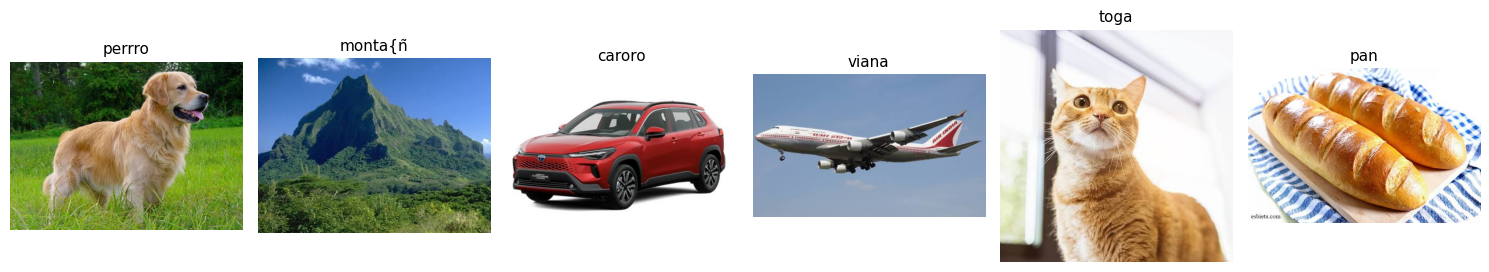

In [12]:
fig, axes = plt.subplots(1, len(rutas), figsize=(15, 3))
for ax, (nombre, ruta) in zip(axes, rutas.items()):
    ax.imshow(Image.open(ruta))
    ax.set_title(nombre, fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Generar embeddings de las imagenes y guardarlas en Chroma

Para cada imagen:

1. La abrimos con PIL.
2. CLIP la convierte en un vector de 512 numeros: `clip.encode(imagen)`.
3. Guardamos en Chroma: `embedding` = vector, `document` = ruta, `metadatos` =
   nombre y tipo.

Como le pasamos los `embeddings` explicitamente, **no** definimos
`embedding_function` en la coleccion. Chroma los guarda tal cual.

In [24]:
from transformers import CLIPProcessor, CLIPModel
import torch
import torch.nn.functional as F

# Cargamos el procesador y modelo CLIP nativo de Hugging Face
clip_hf_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_hf_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

try:
    cliente.delete_collection(NOMBRE_COLECCION)
    print(f"Coleccion '{NOMBRE_COLECCION}' anterior borrada.")
except Exception:
    pass

coleccion = cliente.create_collection(
    name=NOMBRE_COLECCION,
    metadata={"hnsw:space": "cosine"},
)

ids, embeddings, documents, metadatas = [], [], [], []
for nombre, ruta in rutas.items():
    # Abrimos la imagen con PIL
    img = Image.open(ruta)

    # Preprocesamos la imagen
    inputs = clip_hf_processor(images=img, return_tensors="pt")
    with torch.no_grad():
        # Obtenemos las características. Si devuelve un objeto contenedor, extraemos el tensor.
        outputs = clip_hf_model.get_image_features(**inputs)
        if hasattr(outputs, "pooler_output"):
            image_features = outputs.pooler_output
        elif hasattr(outputs, "last_hidden_state"):
            image_features = outputs.last_hidden_state[:, 0]
        else:
            image_features = outputs

        # Normalizamos el tensor con torch.nn.functional.normalize (F)
        image_features = F.normalize(image_features, p=2, dim=-1)
        vec = image_features[0].cpu().numpy()

    ids.append(f"img-{nombre}")
    embeddings.append(vec.tolist())
    documents.append(ruta)         # guardamos la ruta como referencia
    metadatas.append({"nombre": nombre, "tipo": "imagen"})

coleccion.upsert(ids=ids, embeddings=embeddings, documents=documents, metadatas=metadatas)
print(f"Imagenes guardadas en el servidor: {coleccion.count()}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Coleccion 'imagenes' anterior borrada.
Imagenes guardadas en el servidor: 6


## 7. Buscar imagenes con TEXTO

Escribimos una frase. CLIP la convierte en vector (en el **mismo espacio** que
las imagenes). Chroma devuelve las fotos mas cercanas.

Consulta: 'un perro'



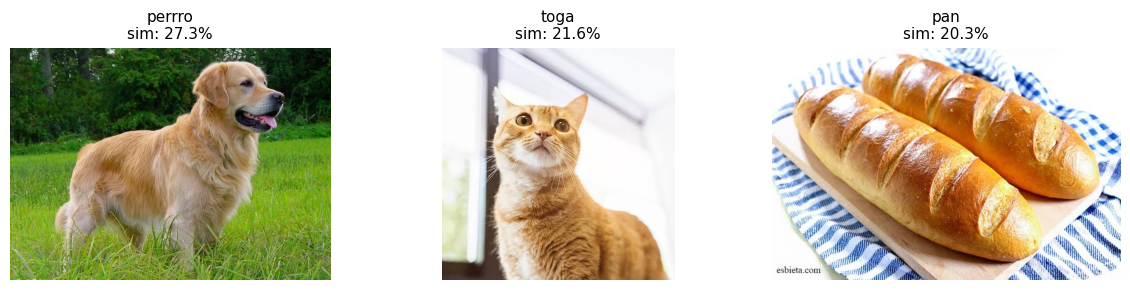

Consulta: 'a car'



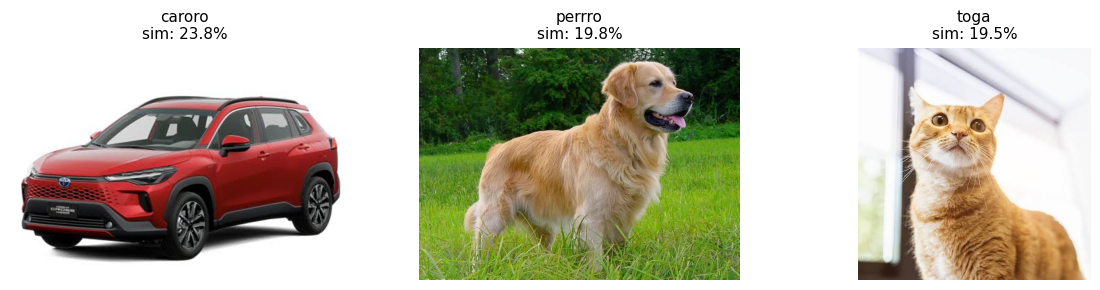

Consulta: 'alimento hecho de harina'



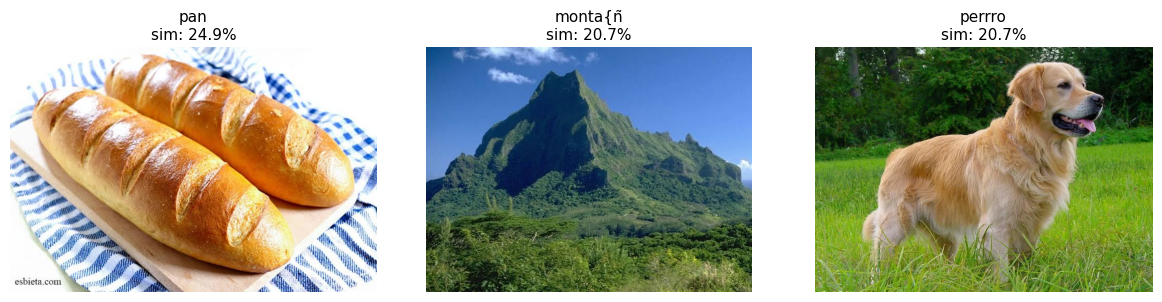

Consulta: 'vehículo que vuela'



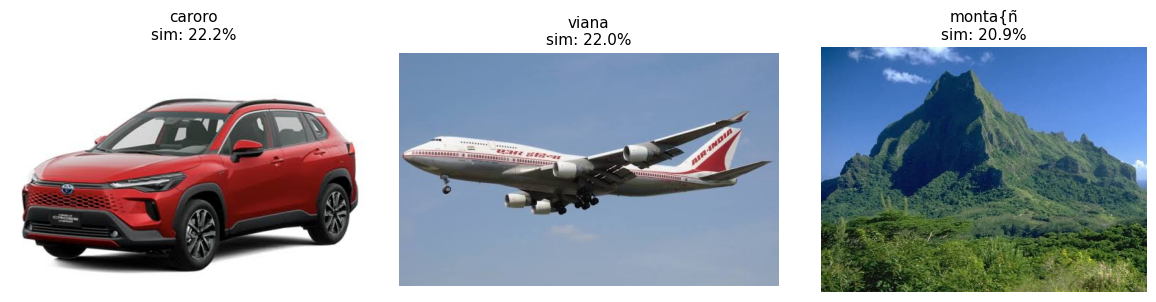

In [25]:
def buscar_con_texto(query, n=3):
    # Vectorizamos la consulta de TEXTO con el mismo CLIP.
    vec_query = clip.encode(query).tolist()

    r = coleccion.query(query_embeddings=[vec_query], n_results=n)
    print(f"Consulta: '{query}'\n")
    fig, axes = plt.subplots(1, len(r["documents"][0]), figsize=(4*n, 3))
    if n == 1: axes = [axes]
    for ax, doc, meta, dist in zip(axes, r["documents"][0],
                                   r["metadatas"][0], r["distances"][0]):
        sim = round((1 - dist) * 100, 1)
        ax.imshow(Image.open(doc))
        ax.set_title(f"{meta['nombre']}\nsim: {sim}%", fontsize=11)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Caso 1: texto que describe la imagen literalmente.
buscar_con_texto("un perro")

# Caso 2: texto en ingles.
buscar_con_texto("a car")

# Caso 3: descripcion sin palabras en comun con el nombre del archivo.
buscar_con_texto("alimento hecho de harina")

# Caso 4: otra descripcion sin palabras en comun.
buscar_con_texto("vehículo que vuela")

Consulta: 'un perro'



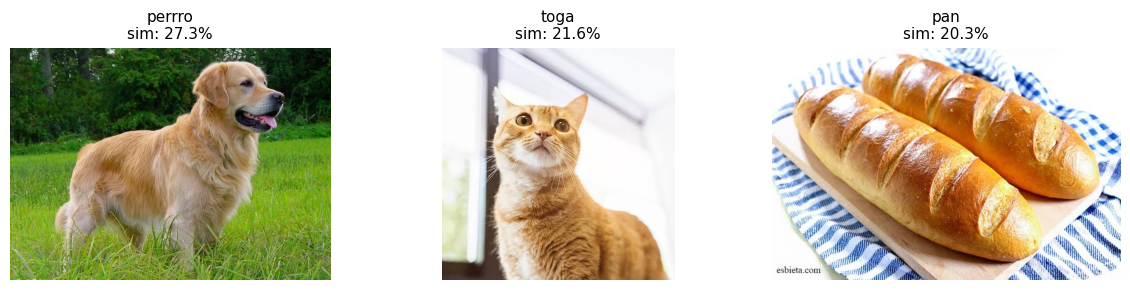

In [27]:
buscar_con_texto("un perro")

## 8. La magia: texto que NO comparte palabras con el archivo

Probemos descripciones mas abstractas:

Consulta: 'mamífero que maúlla'



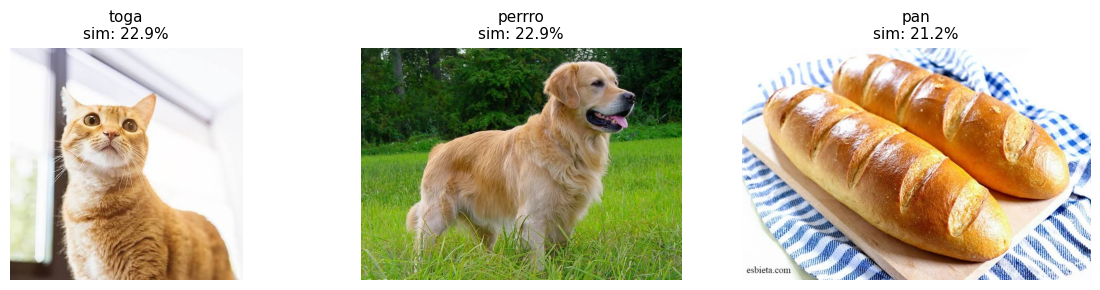

Consulta: 'transporte para cruzar el cielo'



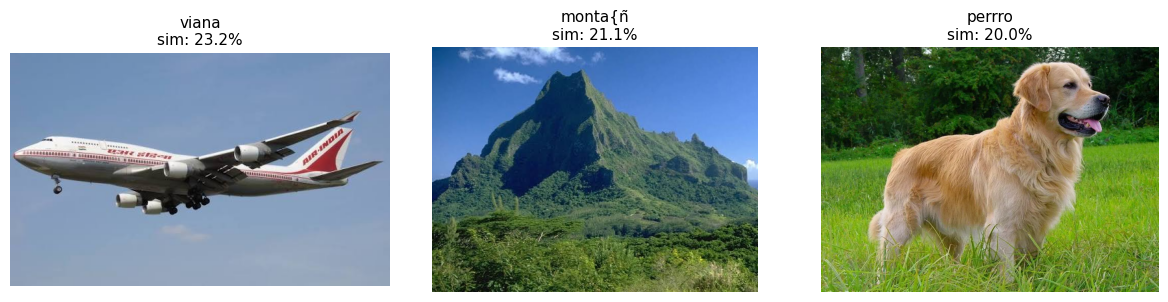

Consulta: 'cima nevada'



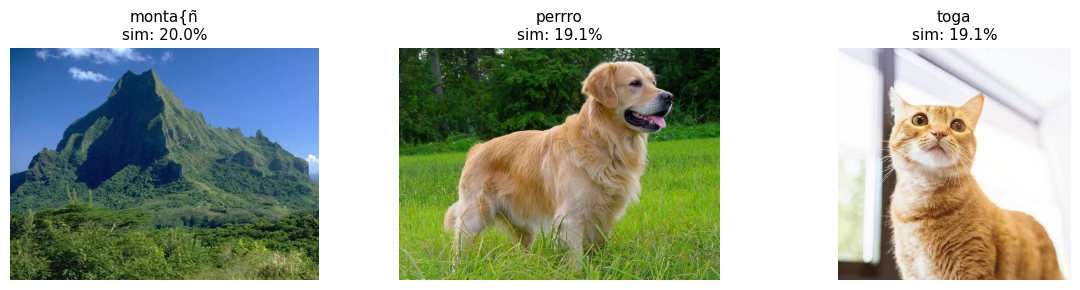

In [26]:
buscar_con_texto("mamífero que maúlla")     # -> gato
buscar_con_texto("transporte para cruzar el cielo")  # -> avion
buscar_con_texto("cima nevada")               # -> montania

## 11. Cierre

- **Chroma no sabe si el vector viene de texto o de imagen**: solo guarda
  vectores. Por eso el mismo servidor sirve para ambos casos.
- **CLIP** es el modelo que pone texto e imagenes **en el mismo espacio**. Una
  foto de perro y la frase "perro" quedan cerca.
- Por eso puedes **escribir "autos deportivos"** y encontrar fotos que nadie
  etiqueto con esa frase. Es lo que hace Google Fotos, Pinterest, etc.

### Idea central (3 puntos)

1. Un modelo convierte **cualquier cosa** (texto, imagen, audio) en un vector.
2. Si los vectores viven en el **mismo espacio**, lo parecido queda cerca.
3. La base vectorial solo hace una cosa: **encontrar los vecinos**.

### Conecta con la clase

| Diapositiva | Donde lo vimos aqui |
|---|---|
| *"No solo texto: todo se vuelve vector"* | CLIP convierte texto e imagen al mismo espacio |
| *"Por eso buscas fotos escribiendo lo que quieres ver"* | Seccion 7-8: buscar con texto |
| *"Lo parecido queda cerca"* | Seccion 9: buscar con imagen devuelve parecidas |

### Que podrias hacer despues

- Probar con **audio**: modelo `clap` hace lo mismo con sonido y texto.
- Probar con **texto largo**: PDFs, documentos (RAG, ejercicio 3).
- **Filtrar por metadatos**: guardar categoria en `metadatas` y filtrar igual
  que en el ejercicio 2.